<div style="background: linear-gradient(135deg,#0f2b46 0%,#1f4e79 55%,#1b7f8c 100%); padding:26px 30px; border-radius:14px; color:white;">
<h1 style="color:white; margin:0;"> Lab 6: Variational Quantum Eigensolver (VQE)</h1>
<h3 style="color:white; margin:6px 0 0 0;">Supply-Chain Risk Optimization with a Hybrid Quantum-Classical Algorithm</h3>
<p style="color:white; margin:10px 0 0 0; font-size:14px;">Quantum Optimization Lab (QCL7350) · Final lab session · Instructor edition (with in-class solutions)</p>
</div>

| | |
|---|---|
| **Session length** | 30 minutes, **2 in-class tasks** |
| **Tools** | `qiskit`, `numpy`, `scipy`, `matplotlib`, `networkx`, `pandas` |
| **Builds on** | Lab 1 to 3 (QUBO), Lab 4 (Hamiltonians, gates), Lab 5 (hybrid loop of QAOA) |
| **Background needed** | Python and a little linear algebra. If you have trained a neural network, you already know half of VQE. |

## Learning objectives

By the end of this lab you will be able to:

1. Turn a real business decision (supplier selection under risk) into a QUBO and then into a qubit **Hamiltonian**.
2. Explain the **variational principle** and the 7-step **VQE workflow** in plain words.
3. Build a parameterized quantum circuit (**ansatz**), train it with a classical optimizer, and read the answer.
4. Compare **5 classical optimizers** (SPSA, COBYLA, Nelder-Mead, L-BFGS-B, ADAM) and explain their trade-offs.
5. Judge honestly where VQE helps compared to classical methods, and where it does not (yet).

### Setup
Run the cell below once. On Google Colab or a fresh machine, uncomment the `pip` line first.

In [ ]:
!pip install qiskit numpy scipy matplotlib networkx pandas pylatexenc -q

import itertools, math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy.optimize import minimize

import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp, Statevector

warnings.filterwarnings("ignore")
RNG_SEED = 7

# One colour language for the whole lab
NAVY, AMBER, GREEN, RED, GREY, TEAL, PURPLE = "#1f4e79", "#e0a458", "#2e8b57", "#b7472a", "#9ca3af", "#1b7f8c", "#6a4c93"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

print("qiskit :", qiskit.__version__)
print("numpy  :", np.__version__)
print("Environment ready ✅")

---
# Part 0 · NovaChip's supplier crisis 

> **Monday, 8:00 AM.** NovaChip Electronics builds the AI accelerator chip inside half the laptops sold this year. Overnight, a typhoon warning closed two ports in the South China Sea. Last year a similar event stopped NovaChip's assembly line for **11 days** and cost **$40 million**.
>
> The CEO walks into the analytics team's room (that is **you**) with one question:
>
> ### *"Which **three** suppliers should we contract for next quarter, so that **one bad event cannot stop our line**?"*

**What we know.** Six qualified suppliers, each with an **individual risk score** (0 to 10, from delivery history, financial health and geopolitical exposure). Some pairs also share a **hidden common risk**: the same shipping lane, the same storm belt, the same freight forwarder. If one fails, the other is likely to fail too.

**Company policy.** Triple sourcing: contract **exactly 3** suppliers.

**Goal.** Minimize **total portfolio risk** = individual risks + shared (correlated) risks.

In [ ]:
# ---------- The six qualified suppliers ----------
SUPPLIERS = [
    # name,        country,     region,   risk score, (x, y) position on a schematic world map
    ("Shenzhen",  "China",     "Asia",    1.5, (110, 38)),
    ("Taipei",    "Taiwan",    "Asia",    2.5, (140, 18)),
    ("Penang",    "Malaysia",  "Asia",    3.0, (104, -2)),
    ("Pune",      "India",     "Asia",    3.5, ( 62, 18)),
    ("Monterrey", "Mexico",    "America", 4.5, (-95, 20)),
    ("Dresden",   "Germany",   "Europe",  5.5, ( 10, 50)),
]
NAMES = [s[0] for s in SUPPLIERS]
N = len(SUPPLIERS)            # number of suppliers = number of qubits
K = 3                         # policy: pick exactly 3
r = np.array([s[3] for s in SUPPLIERS])

# ---------- Correlated (shared) risk between pairs ----------
C = np.zeros((N, N))
for i, j in [(0, 1), (0, 2), (1, 2)]:
    C[i, j] = 3.5             # same South China Sea shipping lane and typhoon belt
for i in range(3):
    for j in range(3, 6):
        C[i, j] = 0.3         # different routes: weak link
C[3, 4] = C[3, 5] = 0.4       # Pune ships west via different routes
C[4, 5] = 2.0                 # Monterrey and Dresden use the same Atlantic freight forwarder

pd.DataFrame({"supplier": NAMES, "country": [s[1] for s in SUPPLIERS],
              "region": [s[2] for s in SUPPLIERS], "individual risk": r}).set_index("supplier")

In [ ]:
def draw_network(selected=None, ax=None, title="NovaChip supplier network", ring=GREEN):
    # Map of suppliers: node colour = individual risk, edge width = shared risk.
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 4.6))
    pos = {i: SUPPLIERS[i][4] for i in range(N)}
    from matplotlib.patches import Ellipse
    ax.add_patch(Ellipse((118, 18), 70, 66, color=RED, alpha=0.07))
    ax.text(118, 55, "South China Sea lane\n(shared typhoon risk)", ha="center", color=RED, fontsize=9)
    ax.text(-42, 41, "same Atlantic freight forwarder", ha="center", color=RED, fontsize=8.5, rotation=14)
    for i in range(N):
        for j in range(i + 1, N):
            if C[i, j] > 0:
                strong = C[i, j] >= 2
                ax.plot([pos[i][0], pos[j][0]], [pos[i][1], pos[j][1]],
                        color=RED if strong else GREY, lw=1 + 1.4 * C[i, j],
                        alpha=0.75 if strong else 0.25, zorder=1)
    sc = ax.scatter([pos[i][0] for i in range(N)], [pos[i][1] for i in range(N)], c=r, cmap="RdYlGn_r",
                    vmin=1, vmax=6, s=[260 + 60 * x for x in r], edgecolor="black", zorder=3)
    if selected is not None:
        sel = [i for i in range(N) if selected[i]]
        ax.scatter([pos[i][0] for i in sel], [pos[i][1] for i in sel], s=1100, facecolor="none",
                   edgecolor=ring, linewidth=3.5, zorder=4)
    for i in range(N):
        ax.text(pos[i][0], pos[i][1] - 8, f"{NAMES[i]}\nrisk {r[i]}", ha="center", va="top", fontsize=8.5)
    ax.set_xlim(-125, 165); ax.set_ylim(-22, 68); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(title, fontsize=11.5, fontweight="bold")
    return sc

sc = draw_network()
plt.colorbar(sc, label="individual risk score", shrink=0.8)
plt.text(-120, 62, "line width = shared risk (red = strong)", color=RED, fontsize=9)
plt.show()

> **Quick poll (30 seconds).** Look at the map. Which 3 suppliers would *you* pick? Keep your answer, we will test it in Part 3.

---
# Part 1 · VQE in one picture 

**VQE (Variational Quantum Eigensolver)** finds the lowest-energy state of a Hamiltonian $H$. If we encode "risk" as "energy", **the lowest-energy state is the safest portfolio**.

**For an AI / DS student, VQE is just model training:**

| Machine learning | VQE |
|---|---|
| model $f_\theta(x)$ | quantum circuit $U(\theta)$ (the **ansatz**) |
| weights $\theta$ | rotation angles $\theta$ |
| loss function | energy $E(\theta) = \langle\psi(\theta)\lvert H\rvert\psi(\theta)\rangle$ |
| optimizer (SGD, ADAM) | classical optimizer (COBYLA, SPSA, ADAM, ...) |
| GPU computes the forward pass | **QPU** prepares and measures the state |

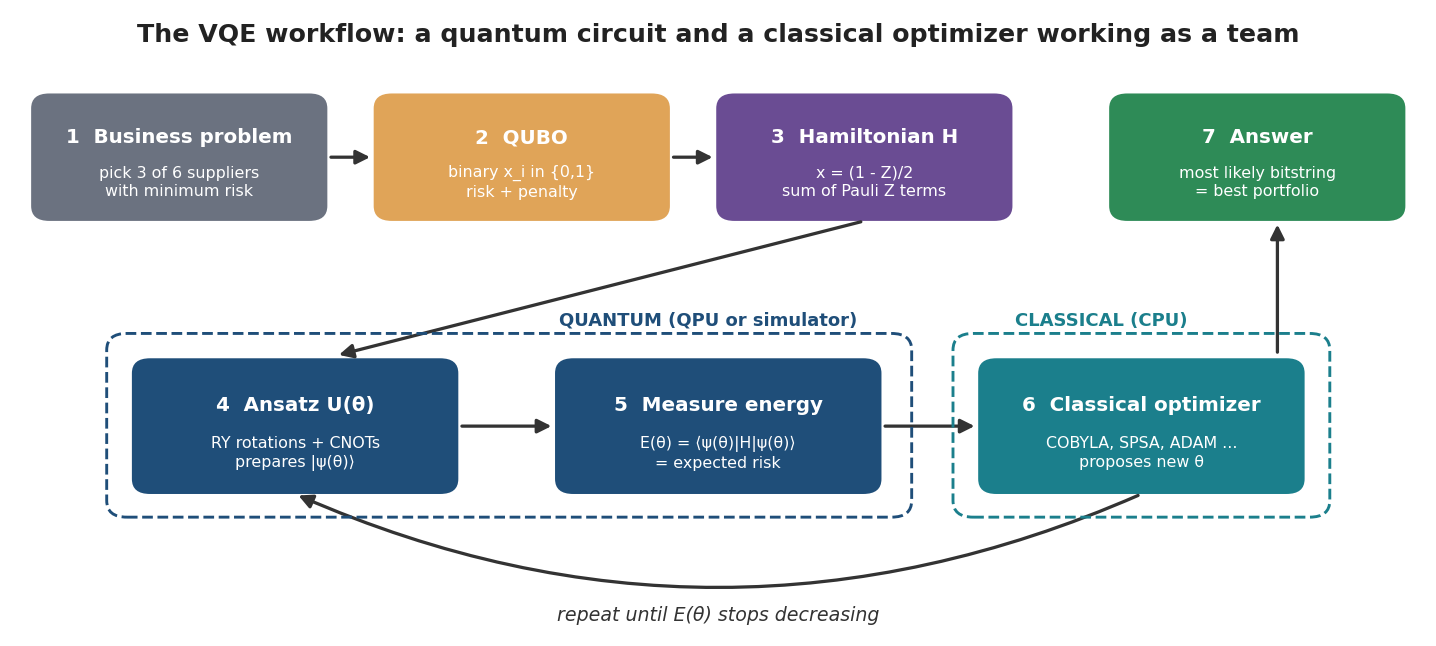

| Step | What happens | Where |
|:---:|---|---|
| 1 | State the business problem | you |
| 2 | Write it as a QUBO (binary variables, penalty for rules) | CPU |
| 3 | Map the QUBO to a Hamiltonian $H$ made of Pauli $Z$ terms | CPU |
| 4 | Prepare a trial state $\lvert\psi(\theta)\rangle$ with a parameterized circuit | QPU |
| 5 | Measure the energy $E(\theta)$ | QPU |
| 6 | A classical optimizer proposes better angles $\theta$, go back to step 4 | CPU |
| 7 | Read the most likely bitstring: that is the answer | CPU |

---
# Part 2 · From business problem to Hamiltonian

**Step 2a: decision variables.** One bit per supplier: $x_i = 1$ if we contract supplier $i$, else $0$. Six suppliers give $2^6 = 64$ possible choices.

**Step 2b: objective (risk) plus a penalty for breaking the "exactly 3" rule.**

$$
\text{Risk}(x) = \underbrace{\sum_i r_i x_i}_{\text{individual risk}} + \underbrace{\sum_{i<j} C_{ij}\, x_i x_j}_{\text{shared risk}} + \underbrace{P\Big(\sum_i x_i - K\Big)^2}_{\text{policy penalty}}
$$

The penalty is $0$ for any valid portfolio and costs $P$ for every supplier too many or too few. We use $P = 8$, larger than the risk any single supplier adds, so breaking the rule never pays (we verify this by brute force below).

**Step 3: QUBO to Hamiltonian.** Each bit becomes a qubit measured in the $Z$ basis: $\;x_i = \dfrac{1 - Z_i}{2}$. Substituting gives

$$
H = \sum_i h_i Z_i + \sum_{i<j} J_{ij} Z_i Z_j + \text{const}
$$

$H$ is diagonal: each basis state $\lvert x\rangle$ is an eigenstate and its energy **equals the portfolio risk**. So **ground state of $H$ = safest valid portfolio**.

In [ ]:
P_PENALTY = 8.0

def build_qubo(r, C, K, P):
    # Return (linear, quadratic, constant) of Risk(x) = sum lin_i x_i + sum_{i<j} Q_ij x_i x_j + const.
    n = len(r)
    lin = r + P * (1 - 2 * K)                      # from P(sum x - K)^2 with x_i^2 = x_i
    quad = np.triu(C, 1) + 2 * P * np.triu(np.ones((n, n)), 1)
    return lin, quad, P * K * K

def qubo_to_hamiltonian(lin, quad, const):
    # Substitute x_i = (1 - Z_i)/2 and collect Pauli terms.
    n = len(lin)
    h, offset, terms = np.zeros(n), const, []
    for i in range(n):
        offset += lin[i] / 2;  h[i] -= lin[i] / 2
        for j in range(i + 1, n):
            if quad[i, j]:
                offset += quad[i, j] / 4;  h[i] -= quad[i, j] / 4;  h[j] -= quad[i, j] / 4
                terms.append(("ZZ", [i, j], quad[i, j] / 4))
    terms += [("Z", [i], h[i]) for i in range(n)]
    return SparsePauliOp.from_sparse_list(terms, num_qubits=n), offset

H, OFFSET = qubo_to_hamiltonian(*build_qubo(r, C, K, P_PENALTY))

# Energy of every basis state (Qiskit order: bit i of the index = qubit i = supplier i)
ALL_X = (np.arange(2**N)[:, None] >> np.arange(N)) & 1
ENERGIES = H.to_matrix(sparse=True).diagonal().real + OFFSET
direct = np.array([r @ x + x @ C @ x + P_PENALTY * (x.sum() - K) ** 2 for x in ALL_X])
OPT_INDEX = int(np.argmin(ENERGIES))
FEASIBLE = ALL_X.sum(axis=1) == K

def portfolio(idx_or_bits):
    bits = ALL_X[idx_or_bits] if np.isscalar(idx_or_bits) else idx_or_bits
    return [NAMES[i] for i in range(N) if bits[i]]

print(f"Hamiltonian: {len(H)} Pauli terms on {N} qubits")
print("Energies equal the risk formula for all 64 bitstrings:", np.allclose(ENERGIES, direct))
print("Ground state is a valid 3-supplier portfolio        :", bool(FEASIBLE[OPT_INDEX]))
print(f"Ground state = {portfolio(OPT_INDEX)}  with risk {ENERGIES[OPT_INDEX]:.1f}")

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1, 1.35]})

M = np.diag(r) + C + C.T
im = axs[0].imshow(M, cmap="RdYlGn_r", vmin=0, vmax=6)
for i in range(N):
    for j in range(N):
        if M[i, j]:
            axs[0].text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", fontsize=9,
                        color="white" if M[i, j] > 4 else "black")
axs[0].set_xticks(range(N)); axs[0].set_xticklabels(NAMES, rotation=40, ha="right")
axs[0].set_yticks(range(N)); axs[0].set_yticklabels(NAMES); axs[0].grid(False)
axs[0].set_title("Risk matrix\n(diagonal = individual, off-diagonal = shared)")
plt.colorbar(im, ax=axs[0], shrink=0.8)

order = np.argsort(ENERGIES)
cols = [GREEN if k == OPT_INDEX else (NAVY if FEASIBLE[k] else GREY) for k in order]
axs[1].bar(range(2**N), ENERGIES[order], color=cols, width=1.0)
axs[1].set_xlabel("all 64 bitstrings, sorted by energy"); axs[1].set_ylabel("energy = risk")
axs[1].set_title("Energy landscape of H")
axs[1].bar(0, 0, color=GREEN, label="ground state (best portfolio)")
axs[1].bar(0, 0, color=NAVY, label="valid portfolios (exactly 3)")
axs[1].bar(0, 0, color=GREY, label="invalid (penalised)")
axs[1].legend(loc="upper left")
plt.tight_layout(); plt.show()

---
# Part 3 · Classical baselines: greedy and brute force 

Two classical strategies a data team would try first:

- **Greedy:** pick the 3 suppliers with the lowest individual risk. Fast, intuitive, and blind to shared risk.
- **Brute force:** check every valid portfolio, $\binom{6}{3} = 20$ here. Exact, but the count explodes with more suppliers.

In [ ]:
greedy_bits = np.zeros(N, dtype=int)
greedy_bits[np.argsort(r)[:K]] = 1
greedy_idx = int(sum(b << i for i, b in enumerate(greedy_bits)))

feasible_idx = [k for k in range(2**N) if FEASIBLE[k]]
ranked = sorted(feasible_idx, key=lambda k: ENERGIES[k])
greedy_rank = ranked.index(greedy_idx) + 1

print(f"Greedy pick : {portfolio(greedy_idx)}   risk = {ENERGIES[greedy_idx]:.1f}   rank {greedy_rank} of {len(ranked)}")
print(f"Brute force : {portfolio(OPT_INDEX)}   risk = {ENERGIES[OPT_INDEX]:.1f}   rank 1 of {len(ranked)}")
print(f"Greedy carries {100 * (ENERGIES[greedy_idx] / ENERGIES[OPT_INDEX] - 1):.0f}% more risk than the optimum.")

fig, ax = plt.subplots(figsize=(10, 5))
labels = [" + ".join(n[:4] for n in portfolio(k)) for k in ranked]
cols = [GREEN if k == OPT_INDEX else (RED if k == greedy_idx else NAVY) for k in ranked]
ax.barh(range(len(ranked)), [ENERGIES[k] for k in ranked], color=cols)
ax.set_yticks(range(len(ranked))); ax.set_yticklabels(labels, fontsize=8.5); ax.invert_yaxis()
for i, k in enumerate(ranked):
    ax.text(ENERGIES[k] + 0.1, i, f"{ENERGIES[k]:.1f}", va="center", fontsize=8)
ax.set_xlabel("total portfolio risk")
ax.set_title("All 20 valid portfolios, ranked (green = optimum, red = greedy)")
plt.tight_layout(); plt.show()

**👀 The twist.** The three individually safest suppliers (Shenzhen, Taipei, Penang) form the **riskiest portfolio of all 20**, because all three sit on the same shipping lane: one typhoon takes out the whole portfolio. The optimum keeps the cheapest supplier and **diversifies** across regions (Shenzhen + Pune + Monterrey), cutting risk by 40%.

Greedy looks at one supplier at a time. The risk lives in the **interactions**. That is exactly what a Hamiltonian captures, and what VQE will optimize.

Brute force found the answer here, but it must check $\binom{n}{n/2}$ portfolios: 20 for 6 suppliers, about $10^{14}$ for 50, and about $10^{29}$ for 100.

---
# Part 4 · Building and running VQE 

## 4.1 The variational principle: why minimizing works

For **any** quantum state $\lvert\psi\rangle$, the measured energy can never go below the true ground-state energy $E_0$:

$$
E(\theta) = \langle\psi(\theta)\lvert H\rvert\psi(\theta)\rangle \;\ge\; E_0 .
$$

So we can search over states freely: the lower the energy we reach, the closer we are to the answer. A one-qubit toy shows it. With $H = Z + 0.5X$ and $\lvert\psi(\theta)\rangle = R_Y(\theta)\lvert 0\rangle$, the energy curve never dips below $E_0$, and touches it at the best angle.

In [ ]:
H_toy = SparsePauliOp(["Z", "X"], coeffs=[1.0, 0.5])
E0_toy = np.linalg.eigvalsh(H_toy.to_matrix()).min()

thetas = np.linspace(0, 2 * np.pi, 200)
energies_toy = []
for t in thetas:
    qc = QuantumCircuit(1); qc.ry(t, 0)
    energies_toy.append(Statevector(qc).expectation_value(H_toy).real)     # Qiskit computes <psi|H|psi>
energies_toy = np.array(energies_toy)
best = thetas[np.argmin(energies_toy)]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(thetas, energies_toy, color=NAVY, lw=2.5, label=r"$E(\theta)$ for $R_Y(\theta)|0\rangle$")
ax.axhline(E0_toy, color=RED, ls="--", label=f"true ground energy E0 = {E0_toy:.3f}")
ax.fill_between(thetas, E0_toy - 0.6, E0_toy, color=RED, alpha=0.08, label="forbidden: no state goes below E0")
ax.plot(best, energies_toy.min(), "*", color=AMBER, ms=18, mec="black", label=f"VQE minimum at θ = {best:.2f}")
ax.set_xlabel("θ (radians)"); ax.set_ylabel("energy"); ax.set_ylim(E0_toy - 0.6, 1.4)
ax.set_title("Variational principle: the energy is bounded below by E0"); ax.legend(fontsize=8.5, loc="upper right")
plt.tight_layout(); plt.show()

## 4.2 The ansatz: our trainable quantum circuit

We use a **hardware-efficient ansatz**: layers of $R_Y(\theta)$ rotations (the trainable knobs) separated by a chain of CNOT gates (which let qubits share information, creating entanglement). `reps` = number of CNOT layers, so a circuit has $N \times (\text{reps}+1)$ parameters.

**Smart start.** We initialise the first layer at $\theta = \pi/2$ and the rest near $0$, plus a little noise. That prepares (almost) the **uniform superposition**: every portfolio equally likely, no bias. Training then shifts probability toward safe portfolios.

In [ ]:
def build_ansatz(reps):
    # Hardware-efficient ansatz: [RY layer, CNOT chain] x reps, then a final RY layer.
    theta = ParameterVector("θ", N * (reps + 1))
    qc, k = QuantumCircuit(N), 0
    for layer in range(reps + 1):
        for q in range(N):
            qc.ry(theta[k], q); k += 1
        if layer < reps:
            qc.barrier()
            for q in range(N - 1):
                qc.cx(q, q + 1)
            qc.barrier()
    return qc

def initial_point(reps, seed):
    rng = np.random.default_rng(seed)
    x0 = np.r_[np.full(N, np.pi / 2), np.zeros(N * reps)]        # uniform superposition start
    return x0 + rng.normal(0, 0.3, N * (reps + 1))               # small random nudge

ansatz_demo = build_ansatz(reps=2)
print(f"reps = 2 : {ansatz_demo.num_parameters} parameters, {ansatz_demo.count_ops().get('cx', 0)} CNOTs, depth {ansatz_demo.depth()}")
print("Qubit q_i = supplier i:", ", ".join(f"q{i} = {n}" for i, n in enumerate(NAMES)))
try:
    display(ansatz_demo.draw("mpl", fold=-1, scale=0.62))
except Exception:
    print(ansatz_demo.draw(fold=140))

## 4.3 Measuring the energy (step 5)

On a quantum computer we would run the circuit thousands of times and average the measured risks. In simulation we can compute the exact output distribution $p_\theta(x)$, and the energy is simply the **expected risk**:

$$
E(\theta) = \sum_{x} p_\theta(x)\, \text{Risk}(x)
$$

DS view: the circuit is a **generative model** over the 64 portfolios, and training lowers the expected risk of what it generates.

To keep the live demo snappy we use a small NumPy statevector simulator for this exact circuit (about 20x faster than rebuilding the Qiskit circuit at every step). The cell checks it is **identical to Qiskit**.

In [ ]:
def simulate_state(theta, reps):
    # Statevector of build_ansatz(reps) at angles theta (real amplitudes, Qiskit qubit order).
    psi = np.zeros((2,) * N); psi[(0,) * N] = 1.0
    k = 0
    for layer in range(reps + 1):
        for q in range(N):
            c, s = np.cos(theta[k] / 2), np.sin(theta[k] / 2); k += 1
            ax = N - 1 - q                                         # qubit q lives on axis N-1-q
            psi = np.moveaxis(np.tensordot(np.array([[c, -s], [s, c]]), psi, axes=([1], [ax])), 0, ax)
        if layer < reps:
            for q in range(N - 1):                                 # CNOT(q -> q+1)
                ctrl, targ = N - 1 - q, N - 2 - q
                sl = [slice(None)] * N; sl[ctrl] = 1; sl = tuple(sl)
                psi = psi.copy(); psi[sl] = np.flip(psi[sl], axis=targ)
    return psi.reshape(-1)

def vqe_energy(theta, reps):
    probs = simulate_state(theta, reps) ** 2                       # Born rule: p(x) = |amplitude|^2
    return probs @ ENERGIES                                        # expected risk

# Check against Qiskit on random angles
t_test = np.random.default_rng(1).uniform(0, 2 * np.pi, N * 3)
qiskit_state = Statevector(build_ansatz(2).assign_parameters(t_test))
print("NumPy simulator matches Qiskit statevector:", np.allclose(qiskit_state.data.real, simulate_state(t_test, 2)))
print("Energy matches Qiskit <psi|H|psi> + offset :",
      np.isclose(qiskit_state.expectation_value(H).real + OFFSET, vqe_energy(t_test, 2)))
print()
uniform_start = np.r_[np.full(N, np.pi / 2), np.zeros(2 * N)]          # no noise: exact uniform superposition
print(f"Energy of the uniform start    : {vqe_energy(uniform_start, 2):6.2f}  (= mean risk of all 64 bitstrings: {ENERGIES.mean():.2f})")
print(f"Energy of the optimal portfolio: {ENERGIES[OPT_INDEX]:6.2f}  (this is what VQE should reach)")

## 4.4 The hybrid loop (steps 4 to 6)

`run_vqe` is the whole workflow in one function. Each call to the cost function is one **circuit evaluation** (on hardware, one batch of shots). We count them, because on a real QPU they are what costs time and money. Optimizers live in a dictionary, so Task 2 can plug in new ones.

In [ ]:
def parameter_shift_gradient(f, theta):
    # Exact gradient for RY circuits: dE/dθ_k = [E(θ + π/2 e_k) - E(θ - π/2 e_k)] / 2.
    g = np.zeros_like(theta)
    for k in range(len(theta)):
        shift = np.zeros_like(theta); shift[k] = np.pi / 2
        g[k] = (f(theta + shift) - f(theta - shift)) / 2
    return g

def opt_cobyla(f, grad, x0, budget, seed):
    return minimize(f, x0, method="COBYLA", options={"maxiter": budget}).x

OPTIMIZERS = {"COBYLA": opt_cobyla}       # more optimizers are added in Task 2

def run_vqe(reps=2, optimizer="COBYLA", seed=0, budget=600, cost=None):
    # Train the ansatz and return a summary dictionary.
    cost = cost or (lambda probs: probs @ ENERGIES)
    history, thetas = [], []
    def f(theta):                                       # one circuit evaluation
        val = cost(simulate_state(theta, reps) ** 2)
        history.append(val); thetas.append(np.array(theta))
        return val
    grad = lambda theta: parameter_shift_gradient(f, theta)
    t0 = time.perf_counter()
    theta = OPTIMIZERS[optimizer](f, grad, initial_point(reps, seed), budget, seed)
    probs = simulate_state(theta, reps) ** 2
    return dict(theta=theta, probs=probs, energy=probs @ ENERGIES, history=np.array(history), thetas=thetas,
                evals=len(history), success=int(np.argmax(probs)) == OPT_INDEX,
                p_opt=probs[OPT_INDEX], seconds=time.perf_counter() - t0, reps=reps, optimizer=optimizer)

In [ ]:
REPS_MAIN = 2
vqe = run_vqe(reps=REPS_MAIN, optimizer="COBYLA", seed=0, budget=600)

print(f"Circuit evaluations : {vqe['evals']}   ({vqe['seconds']:.1f} s)")
print(f"Final energy        : {vqe['energy']:.3f}   (optimum {ENERGIES[OPT_INDEX]:.1f})")
print(f"P(optimal portfolio): {vqe['p_opt']:.3f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(vqe["history"], color=NAVY, alpha=0.35, lw=1, label="energy at each evaluation")
ax.plot(np.minimum.accumulate(vqe["history"]), color=NAVY, lw=2.5, label="best so far")
ax.axhline(ENERGIES[OPT_INDEX], color=GREEN, ls="--", lw=2, label="optimal risk (brute force)")
ax.axhline(ENERGIES[greedy_idx], color=RED, ls=":", lw=2, label="greedy risk")
ax.set_ylim(ENERGIES[OPT_INDEX] - 1, ENERGIES.mean() + 3)
ax.set_xlabel("circuit evaluations"); ax.set_ylabel("energy = expected risk")
ax.set_title("VQE training curve (COBYLA, reps = 2)"); ax.legend(loc="upper right", fontsize=8.5)
plt.tight_layout(); plt.show()

## 4.5 Reading the answer (step 7)

The trained circuit is a probability distribution over the 64 portfolios. Watch how training moves probability from "every portfolio equally likely" onto the safest one. The last panel is a **1,024-shot Qiskit sample** of the trained circuit, exactly what a QPU would return.

In [ ]:
def show_top(probs, ax, title, top=6):
    idx = [k for k in np.argsort(probs)[::-1][:top] if probs[k] > 0]
    cols = [GREEN if k == OPT_INDEX else (NAVY if FEASIBLE[k] else GREY) for k in idx]
    labels = ["+".join(n[:4] for n in portfolio(k)) or "none" for k in idx]
    ax.bar(range(len(idx)), probs[idx], color=cols, edgecolor="black")
    ax.set_xticks(range(len(idx))); ax.set_xticklabels(labels, rotation=40, ha="right", fontsize=7.5)
    ax.set_ylim(0, 1.05); ax.set_title(title, fontsize=9.5)

# Qiskit check: plug the trained angles into the real Qiskit circuit and sample 1,024 shots
final_state = Statevector(build_ansatz(REPS_MAIN).assign_parameters(vqe["theta"]))
final_state.seed(RNG_SEED)
counts = final_state.sample_counts(shots=1024)
best_bits = max(counts, key=counts.get)              # Qiskit prints qubit 0 on the right
best_idx = int(best_bits, 2)
shots = np.zeros(2**N)
for b, c in counts.items():
    shots[int(b, 2)] = c / 1024

fig, axs = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, step in zip(axs[:3], [0, 25, 80]):
    p = simulate_state(vqe["thetas"][step], REPS_MAIN) ** 2
    show_top(p, ax, f"after {step} evaluations\nE = {p @ ENERGIES:.1f},  P(opt) = {p[OPT_INDEX]:.2f}")
show_top(shots, axs[3], f"trained: 1,024 Qiskit shots\nP(opt) = {shots[OPT_INDEX]:.2f}")
axs[0].set_ylabel("probability")
fig.suptitle("Training moves probability onto the safest portfolio (green = optimal, blue = valid, grey = invalid)", fontsize=11)
plt.tight_layout(); plt.show()

print(f"Most frequent bitstring: {best_bits}  ->  {portfolio(best_idx)}  ({counts[best_bits]} of 1024 shots)")
print(f"Qiskit energy of trained state: {final_state.expectation_value(H).real + OFFSET:.3f}")

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6))
draw_network(greedy_bits, ax=axs[0], title=f"Greedy pick: risk {ENERGIES[greedy_idx]:.1f}  (worst of 20)", ring=RED)
draw_network(ALL_X[best_idx], ax=axs[1], title=f"VQE pick: risk {ENERGIES[best_idx]:.1f}  (optimal)")
plt.tight_layout(); plt.show()

print("📋 Recommendation to the CEO")
print(f"   Contract: {', '.join(portfolio(best_idx))}")
print(f"   Portfolio risk {ENERGIES[best_idx]:.1f} vs {ENERGIES[greedy_idx]:.1f} for the 'obvious' pick: "
      f"{100 * (1 - ENERGIES[best_idx] / ENERGIES[greedy_idx]):.0f}% lower risk, one supplier per shipping corridor.")

**👀 What to notice.**
- The energy dropped from about 26 (the uniform start, where every portfolio is equally likely) to the optimum 10.5 in a few hundred evaluations.
- Nearly all probability ends on **one bitstring**: the optimal portfolio. Our Hamiltonian is diagonal, so its ground state is a single bitstring, and VQE learns to concentrate on it.
- Training is a **local search**: a bad starting point can get stuck in a local minimum. That is why the two tasks below matter.

### In-class Task 1

A deeper ansatz (more `reps`) has more parameters and more entangling gates. It is more **expressive**, but also harder to train, and on real hardware every extra CNOT adds noise.

1. Run the cell below with `REPS = 1`, then `2`, then `3`.
2. For each, note the number of **successful starts** (most likely bitstring = optimal portfolio), the mean **P(optimal)**, and the parameter count.
3. **Discuss:** is deeper always better? What would you choose on a noisy real QPU?

| `REPS` | parameters | CNOTs | successful starts (of 5) | mean P(optimal) |
|:------:|:----------:|:-----:|:------------------------:|:---------------:|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |


In [ ]:
# ===================== 🧪 IN-CLASS TASK 1: change REPS =====================
REPS     = 3      # ansatz depth: try 1, 2, 3
N_STARTS = 5      # independent random starting points
# ==========================================================================

runs = [run_vqe(reps=REPS, optimizer="COBYLA", seed=s, budget=600) for s in range(N_STARTS)]
qc_t = build_ansatz(REPS)
print(f"REPS = {REPS}:  {qc_t.num_parameters} parameters, {qc_t.count_ops().get('cx', 0)} CNOTs")
print(f"Successful starts : {sum(run['success'] for run in runs)} of {N_STARTS}")
print(f"Mean P(optimal)   : {np.mean([run['p_opt'] for run in runs]):.2f}")
print(f"Mean final energy : {np.mean([run['energy'] for run in runs]):.2f}   (optimum {ENERGIES[OPT_INDEX]:.1f})")

fig, ax = plt.subplots(figsize=(8.5, 3.5))
for s, run in enumerate(runs):
    ax.plot(np.minimum.accumulate(run["history"]), color=GREEN if run["success"] else RED, alpha=0.8,
            label="found optimum" if run["success"] else "stuck in local minimum")
ax.axhline(ENERGIES[OPT_INDEX], color="black", ls="--", lw=1, label="optimum")
ax.set_ylim(ENERGIES[OPT_INDEX] - 0.5, ENERGIES[OPT_INDEX] + 6)
ax.set_xlabel("circuit evaluations"); ax.set_ylabel("best energy so far")
handles, labels = ax.get_legend_handles_labels(); uniq = dict(zip(labels, handles))
ax.legend(uniq.values(), uniq.keys(), fontsize=8.5)
ax.set_title(f"Task 1: {N_STARTS} training runs with REPS = {REPS} (green = optimum found)")
plt.tight_layout(); plt.show()

## 4.6 Meet the classical optimizers

The quantum computer only evaluates $E(\theta)$. **Choosing the next $\theta$ is a classical job**, and the choice of optimizer matters a lot.

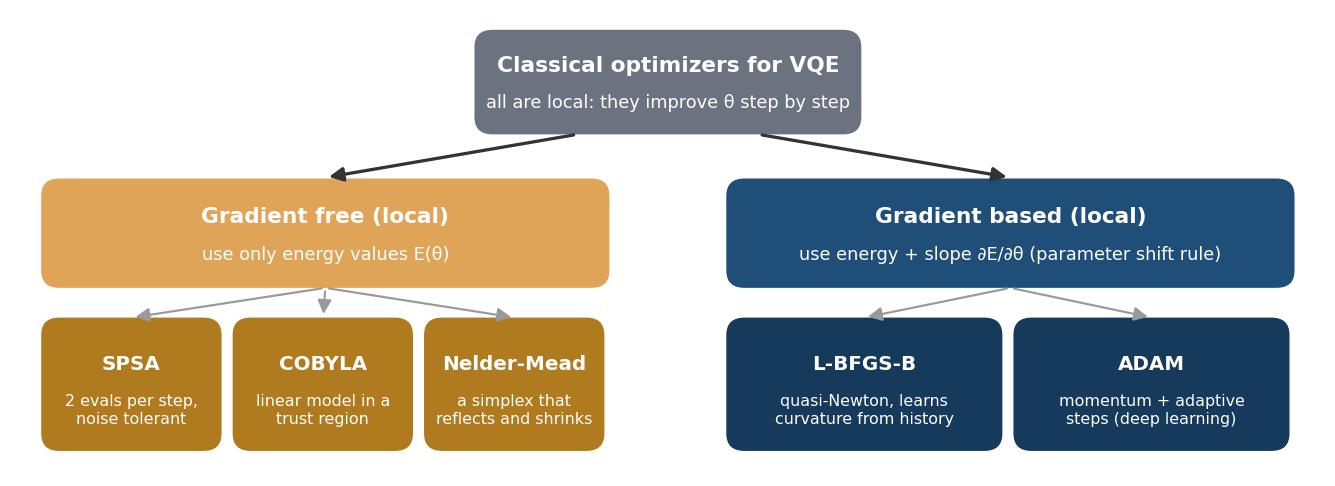

| Family | Optimizer | Simple definition | Cost per step |
|---|---|---|---|
| **Gradient free (local)** | **SPSA** (Simultaneous Perturbation Stochastic Approximation) | Nudge **all** parameters at once in a random $\pm$ direction, compare two energies, and step downhill. A cheap, noisy gradient guess. | **2** evaluations, whatever the number of parameters |
| | **COBYLA** (Constrained Optimization BY Linear Approximation) | Fit a simple **linear model** of $E(\theta)$ inside a small "trust region", jump to its best point, then shrink or grow the region. | about 1 evaluation |
| | **Nelder-Mead** | Keep a **simplex** of $p+1$ points. Repeatedly replace the worst point by reflecting, expanding or shrinking the shape. | 1 or 2 evaluations |
| **Gradient based (local)** | **L-BFGS-B** | Quasi-Newton: uses gradients plus a short **memory of past gradients** to estimate curvature and take smart, long steps. "B" means it accepts bounds. | 1 gradient = $2p$ evaluations |
| | **ADAM** | Gradient descent with **momentum** and a **per-parameter adaptive step size**. The default optimizer of deep learning. | 1 gradient = $2p$ evaluations |

**Where do quantum gradients come from?** The **parameter-shift rule** gives the *exact* slope of an $R_Y$ circuit from two shifted circuit runs:

$$
\frac{\partial E}{\partial \theta_k} = \frac{E(\theta + \tfrac{\pi}{2}\mathbf{e}_k) - E(\theta - \tfrac{\pi}{2}\mathbf{e}_k)}{2}
$$

With $p = 18$ parameters, one gradient costs $36$ circuit evaluations. That price is the heart of Task 2.

In [ ]:
def opt_nelder_mead(f, grad, x0, budget, seed):
    return minimize(f, x0, method="Nelder-Mead", options={"maxfev": budget, "maxiter": budget, "adaptive": True}).x

def opt_lbfgsb(f, grad, x0, budget, seed):
    max_calls = budget // (2 * len(x0) + 1)                     # each call = 1 energy + 1 gradient (2p evals)
    return minimize(f, x0, jac=grad, method="L-BFGS-B", options={"maxfun": max_calls}).x

def opt_spsa(f, grad, x0, budget, seed, a=0.3, c=0.15, A=20):
    rng, x = np.random.default_rng(seed + 100), x0.copy()
    for k in range(budget // 2):                                # 2 evaluations per step
        ak, ck = a / (k + 1 + A) ** 0.602, c / (k + 1) ** 0.101  # standard SPSA gain schedules
        delta = rng.choice([-1, 1], size=len(x))                 # random +/- direction for every parameter
        g_est = (f(x + ck * delta) - f(x - ck * delta)) / (2 * ck) * delta
        x = x - ak * g_est
    return x

def opt_adam(f, grad, x0, budget, seed, lr=0.1, b1=0.9, b2=0.999, eps=1e-8):
    x, m, v = x0.copy(), np.zeros_like(x0), np.zeros_like(x0)
    for t in range(1, budget // (2 * len(x0)) + 1):             # each step costs one gradient
        g = grad(x)
        m, v = b1 * m + (1 - b1) * g, b2 * v + (1 - b2) * g * g  # momentum and adaptive scale
        x = x - lr * (m / (1 - b1**t)) / (np.sqrt(v / (1 - b2**t)) + eps)
    return x

OPTIMIZERS.update({"SPSA": opt_spsa, "Nelder-Mead": opt_nelder_mead, "L-BFGS-B": opt_lbfgsb, "ADAM": opt_adam})
print("Available optimizers:", list(OPTIMIZERS))

### In-class Task 2

Every optimizer gets the **same budget** of about 1,000 circuit evaluations, the same circuit (`reps = 2`) and the same 5 starting points. A fair race.

1. Run the cell below once for each optimizer: `"SPSA"`, `"COBYLA"`, `"Nelder-Mead"`, `"L-BFGS-B"`, `"ADAM"`.
2. Record successful starts, mean final energy and run time in the table.
3. **Discuss:** gradient-based methods use exact slopes. Why don't they automatically win? Which optimizer would you trust on a *noisy* real QPU?

| Optimizer | Family | Successful Starts (of 5) | Mean Final Energy | Seconds |
|-----------|--------|:------------------------:|:-----------------:|:-------:|
| SPSA | Gradient-free | | | |
| COBYLA | Gradient-free | | | |
| Nelder-Mead | Gradient-free | | | |
| L-BFGS-B | Gradient-based | | | |
| ADAM | Gradient-based | | | |

In [ ]:
# ===================== 🧪 IN-CLASS TASK 2: change OPTIMIZER =====================
OPTIMIZER = "ADAM"   # try: "SPSA", "COBYLA", "Nelder-Mead", "L-BFGS-B", "ADAM"
BUDGET    = 1000       # circuit evaluations allowed per run
N_STARTS  = 5
# ===============================================================================

runs = [run_vqe(reps=2, optimizer=OPTIMIZER, seed=s, budget=BUDGET) for s in range(N_STARTS)]
print(f"{OPTIMIZER}:  successful starts {sum(x['success'] for x in runs)} of {N_STARTS}  |  "
      f"mean final energy {np.mean([x['energy'] for x in runs]):.2f}  |  "
      f"mean evaluations {np.mean([x['evals'] for x in runs]):.0f}  |  "
      f"{np.mean([x['seconds'] for x in runs]):.2f} s per run")

fig, ax = plt.subplots(figsize=(8.5, 3.5))
for x in runs:
    ax.plot(np.minimum.accumulate(x["history"]), color=GREEN if x["success"] else RED, alpha=0.85)
ax.axhline(ENERGIES[OPT_INDEX], color="black", ls="--", lw=1)
ax.set_ylim(ENERGIES[OPT_INDEX] - 0.5, ENERGIES[OPT_INDEX] + 8)
ax.set_xlabel("circuit evaluations"); ax.set_ylabel("best energy so far")
ax.set_title(f"Task 2: {OPTIMIZER} on {N_STARTS} starts (green = optimum found, red = stuck)")
plt.tight_layout(); plt.show()

---
# Part 5 · Why VQE 

In [ ]:
n_sup = np.arange(6, 101, 2)
portfolios = [math.comb(int(k), int(k) // 2) for k in n_sup]

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].semilogy(n_sup, portfolios, color=RED, lw=2.5, label="valid portfolios to check (brute force)")
axs[0].semilogy(n_sup, 16.0 * 2.0**n_sup, color=GREY, lw=2, ls="--", label="bytes to store the state classically")
for k, txt, off in [(6, "today: 20 portfolios", (12, -4)), (50, "50 suppliers:\n1.3e14 portfolios", (12, -22)),
                    (100, "100 suppliers:\n1e29", (-75, -10))]:
    axs[0].plot(k, math.comb(k, k // 2), "o", color=RED)
    axs[0].annotate(txt, (k, math.comb(k, k // 2)), textcoords="offset points", xytext=off, fontsize=8.5)
axs[0].axhline(16e9, color=NAVY, lw=1, ls=":")
axs[0].text(72, 16e9 / 400, "16 GB laptop RAM", color=NAVY, fontsize=8.5)
axs[0].set_xlabel("number of suppliers"); axs[0].set_title("Classical cost explodes exponentially"); axs[0].legend(fontsize=8.5)

axs[1].plot(n_sup, n_sup, color=NAVY, lw=2.5, label="qubits needed (one per supplier)")
axs[1].plot(n_sup, n_sup * 3, color=TEAL, lw=2.5, label="VQE parameters (reps = 2)")
axs[1].plot(n_sup, 2 * (n_sup - 1), color=AMBER, lw=2.5, label="CNOT gates (reps = 2)")
axs[1].set_xlabel("number of suppliers"); axs[1].set_title("VQE circuit resources grow linearly"); axs[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

### ✅ Where VQE has the edge
- **It sees interactions.** Greedy missed the shared shipping-lane risk and picked the worst portfolio. VQE optimizes the full Hamiltonian, so correlations are built in.
- **Linear resources, exponential state.** 100 suppliers need only 100 qubits and a few hundred parameters, while the quantum state lives in a $2^{100}$-dimensional space that no classical computer can even store.
- **Hybrid and flexible.** The same loop solves any problem written as a Hamiltonian: portfolio and supplier selection, scheduling, logistics, and VQE's original home, molecular chemistry.
- **Near-term friendly.** Short circuits plus a classical optimizer tolerate today's noisy hardware better than deep algorithms.

### ⚠️ Reality check (be honest with your CEO)
- At 6 suppliers, brute force is instant. **VQE's advantage can only appear at scale, on real quantum hardware.**
- VQE is a **heuristic**: it can get stuck in local minima (Task 1), it depends on the optimizer (Task 2), and very deep circuits hit barren plateaus.
- Strong classical solvers (integer programming, simulated annealing) remain excellent for problems like this one. Whether VQE beats them on industrial sizes is an **open research question**.

---
# Part 6 · Summary

| Step | Today's version |
|---|---|
| Business problem | NovaChip: pick 3 of 6 suppliers with minimum total risk |
| QUBO | $\sum r_i x_i + \sum C_{ij} x_i x_j + P(\sum x_i - 3)^2$ |
| Hamiltonian | $x_i = (1 - Z_i)/2$, ground state = safest portfolio |
| Ansatz | $R_Y$ layers + CNOT chain, $N(\text{reps}+1)$ parameters |
| Cost | $E(\theta)$ = expected risk of the circuit's output distribution |
| Optimizer | COBYLA, SPSA, Nelder-Mead (gradient free), L-BFGS-B, ADAM (gradient based) |
| Answer | most likely bitstring: **Shenzhen + Pune + Monterrey**, 40% less risk than greedy |

### Three things to remember
1. **VQE = training a quantum model.** The circuit is the model, the energy is the loss, a classical optimizer does the learning.
2. **The Hamiltonian is where the business lives.** Risks and interactions become $Z$ and $ZZ$ terms; the ground state is the decision.
3. **Design choices matter.** Depth, starting point and optimizer decide whether training finds the answer.

**Congratulations on finishing the lab series!** From QUBO (Labs 1 to 3), through Hamiltonians and adiabatic evolution (Lab 4) and QAOA (Lab 5), to VQE today: you now know the full toolkit of quantum optimization.

---
# Exercises (Any 2)

Submit this notebook with all outputs visible. Every exercise reuses functions from this lab; `run_vqe(..., cost=...)` accepts any cost function of the output probabilities.

## Exercise 1 · The board expands the shortlist (scaling)

NovaChip qualifies two more suppliers: **Hanoi** (Vietnam, risk 2.0, on the South China Sea lane) and **Warsaw** (Poland, risk 5.0, shares a rail corridor with Dresden). The policy becomes **exactly 4 of 8** suppliers.

```python
NAMES8 = ["Shenzhen", "Taipei", "Penang", "Pune", "Monterrey", "Dresden", "Hanoi", "Warsaw"]
r8 = np.array([1.5, 2.5, 3.0, 3.5, 4.5, 5.5, 2.0, 5.0])
C8 = np.zeros((8, 8)); C8[:6, :6] = C
C8[0:3, 6] = 3.0          # Hanoi shares the South China Sea lane
C8[3:6, 6] = 0.3
C8[0:3, 7] = 0.3; C8[6, 7] = 0.3; C8[3, 7] = 0.4; C8[4, 7] = 0.5
C8[5, 7] = 2.5            # Warsaw and Dresden share a rail corridor
```

1. Rebuild `N`, `K`, `r`, `C`, `H`, `ENERGIES`, `OPT_INDEX` for this instance (keep $P = 8$) and find the optimum and the greedy rank by brute force.
2. Run VQE with `reps = 2` and `reps = 3`, 5 starts each, `budget = 1000`. Report successful starts and mean P(optimal).
3. In 3 to 4 sentences: compared with 6 suppliers, what happened to training reliability, and what does that suggest for 100 suppliers?

## Exercise 2 · Real hardware is noisy (shot noise)

A QPU estimates energies from a finite number of shots. Write a noisy cost function:

```python
def make_shot_cost(shots, seed=0):
    rng = np.random.default_rng(seed)
    def cost(probs):
        p = np.clip(probs, 0, None); p = p / p.sum()
        counts = rng.multinomial(shots, p)          # simulate measuring the circuit `shots` times
        return counts @ ENERGIES / shots
    return cost
```

1. Run SPSA, COBYLA and L-BFGS-B (`reps = 2`, `budget = 1000`, 5 starts) with `cost=make_shot_cost(64)`, `make_shot_cost(1024)`, and the exact cost.
2. Plot mean final energy against the number of shots for the three optimizers.
3. Explain which optimizer degrades most gracefully under noise, and why (think about how each one uses energy values).

## Exercise 3 · Risk managers love CVaR

Finance measures tail risk with **CVaR** (Conditional Value at Risk). Barkoutsos et al. (2020) showed that optimizing CVaR instead of the mean helps VQE on optimization problems: instead of the average energy, use the average over the **best $\alpha$ fraction** of outcomes.

```python
ORDER = np.argsort(ENERGIES)
def make_cvar_cost(alpha):
    def cost(probs):
        p, e = probs[ORDER], ENERGIES[ORDER]
        take = np.minimum(p, np.maximum(alpha - (np.cumsum(p) - p), 0))   # first alpha of probability mass
        return take @ e / alpha
    return cost
```

1. With `reps = 1` (the hardest case from Task 1) and 10 starts, compare $\alpha = 1.0$ (plain VQE), $0.5$, $0.25$ and $0.1$.
2. Report successful starts and mean P(optimal) for each $\alpha$ in a table and a bar chart.
3. Explain why a smaller $\alpha$ can raise the success rate while *lowering* P(optimal), and why too small an $\alpha$ hurts again.

---
## 📖 References

**VQE**
1. A. Peruzzo et al., "A variational eigenvalue solver on a photonic quantum processor," *Nature Communications* 5, 4213 (2014). [arXiv:1304.3061](https://arxiv.org/abs/1304.3061)
2. J. R. McClean, J. Romero, R. Babbush, A. Aspuru-Guzik, "The theory of variational hybrid quantum-classical algorithms," *New Journal of Physics* 18, 023023 (2016). [arXiv:1509.04279](https://arxiv.org/abs/1509.04279)
3. A. Kandala et al., "Hardware-efficient variational quantum eigensolver for small molecules and quantum magnets," *Nature* 549, 242 (2017). [arXiv:1704.05018](https://arxiv.org/abs/1704.05018)
4. J. Tilly et al., "The Variational Quantum Eigensolver: a review of methods and best practices," *Physics Reports* 986, 1 (2022). [arXiv:2111.05176](https://arxiv.org/abs/2111.05176)
5. P. Kl. Barkoutsos et al., "Improving Variational Quantum Optimization using CVaR," *Quantum* 4, 256 (2020). [arXiv:1907.04769](https://arxiv.org/abs/1907.04769)
6. J. R. McClean et al., "Barren plateaus in quantum neural network training landscapes," *Nature Communications* 9, 4812 (2018). [arXiv:1803.11173](https://arxiv.org/abs/1803.11173)

**Gradients and optimizers**

7. K. Mitarai, M. Negoro, M. Kitagawa, K. Fujii, "Quantum circuit learning," *Physical Review A* 98, 032309 (2018). [arXiv:1803.00745](https://arxiv.org/abs/1803.00745)
8. M. Schuld, V. Bergholm, C. Gogolin, J. Izaac, N. Killoran, "Evaluating analytic gradients on quantum hardware," *Physical Review A* 99, 032331 (2019). [arXiv:1811.11184](https://arxiv.org/abs/1811.11184)
9. J. C. Spall, "Multivariate stochastic approximation using a simultaneous perturbation gradient approximation," *IEEE Transactions on Automatic Control* 37(3), 332 (1992).
10. M. J. D. Powell, "A direct search optimization method that models the objective and constraint functions by linear interpolation," in *Advances in Optimization and Numerical Analysis*, Springer (1994).
11. J. A. Nelder and R. Mead, "A simplex method for function minimization," *The Computer Journal* 7(4), 308 (1965).
12. R. H. Byrd, P. Lu, J. Nocedal, C. Zhu, "A limited memory algorithm for bound constrained optimization," *SIAM Journal on Scientific Computing* 16(5), 1190 (1995).
13. D. P. Kingma and J. Ba, "Adam: A method for stochastic optimization," ICLR (2015). [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)

**Supply chain and diversification**

14. H. Markowitz, "Portfolio selection," *The Journal of Finance* 7(1), 77 (1952). [doi:10.2307/2975974](https://doi.org/10.2307/2975974) The diversification idea behind today's correlated-risk term.
15. A. Lucas, "Ising formulations of many NP problems," *Frontiers in Physics* 2, 5 (2014). [arXiv:1302.5843](https://arxiv.org/abs/1302.5843)

**Software**

16. [Qiskit documentation (IBM Quantum)](https://quantum.cloud.ibm.com/docs) · [SciPy `optimize.minimize`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)

---
<p style="text-align:center; color:#6b7280;"> Thank you for a great semester of quantum optimization!</p>